In [87]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


movies_raw = pd.read_csv('imdb_top_250_movies.csv')

# Section 1: What's the dataset we're using?

## 1.1 What are its columns?

In [88]:
movies_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   250 non-null    str    
 1   url                  250 non-null    str    
 2   primaryTitle         250 non-null    str    
 3   originalTitle        250 non-null    str    
 4   type                 250 non-null    str    
 5   parentImdbId         0 non-null      float64
 6   description          250 non-null    str    
 7   primaryImage         250 non-null    str    
 8   thumbnails           250 non-null    str    
 9   trailer              244 non-null    str    
 10  contentRating        244 non-null    str    
 11  startYear            250 non-null    int64  
 12  endYear              0 non-null      float64
 13  releaseDate          250 non-null    str    
 14  interests            250 non-null    str    
 15  countriesOfOrigin    250 non-null    str    
 16  e

## Example of data

In [89]:
movies_raw.head(1)

,id,url,primaryTitle,originalTitle,type,parentImdbId,description,primaryImage,thumbnails,trailer,...,filmingLocations,productionCompanies,budget,grossWorldwide,genres,isAdult,runtimeMinutes,averageRating,numVotes,metascore
0,tt0111161,https://www.imdb.com/title/tt0111161/,The Shawshank Redemption,The Shawshank Redemption,movie,NaN,After a banker is sentenced to life in Shawsha...,https://m.media-amazon.com/images/M/MV5BMDAyY2...,[{'url': 'https://m.media-amazon.com/images/M/...,https://www.youtube.com/watch?v=xyXX8LXiNJ4,...,"['Butler, Ohio, USA']","[{'id': 'co0040620', 'name': 'Castle Rock Ente...",25000000.0,29425588.0,['Drama'],False,142,9.3,3254168,82.0


# 2. Data Cleaning
do we need everything? NO! Let's cut the useless data! 
and make a clean movies datafram with only the columns we're interested in

In [90]:
movies = movies_raw[["id", "primaryTitle","type","filmingLocations","productionCompanies", "budget", "genres", "isAdult", "runtimeMinutes", "averageRating", "numVotes", "metascore"]]

In [91]:
movies.head()

,id,primaryTitle,type,filmingLocations,productionCompanies,budget,genres,isAdult,runtimeMinutes,averageRating,numVotes,metascore
0,tt0111161,The Shawshank Redemption,movie,"['Butler, Ohio, USA']","[{'id': 'co0040620', 'name': 'Castle Rock Ente...",25000000.0,['Drama'],False,142,9.3,3254168,82.0
1,tt0068646,The Godfather,movie,"[""Forza d'Agrò, Messina, Sicily, Italy""]","[{'id': 'co0023400', 'name': 'Paramount Pictur...",6000000.0,"['Crime', 'Drama']",False,175,9.2,2265838,100.0
2,tt0468569,The Dark Knight,movie,"['Chicago, Illinois, USA']","[{'id': 'co0002663', 'name': 'Warner Bros.'}, ...",185000000.0,"['Crime', 'Thriller']",False,152,9.1,3240614,85.0
3,tt0071562,The Godfather Part II,movie,"['Kaiser Estate - 4000 W Lake Blvd, Homewood, ...","[{'id': 'co0023400', 'name': 'Paramount Pictur...",13000000.0,"['Crime', 'Drama']",False,202,9.0,1519575,90.0
4,tt0167260,The Lord of the Rings: The Return of the King,movie,"['Hinuera Valley, Matamata, Waikato, New Zeala...","[{'id': 'co0046718', 'name': 'New Line Cinema'...",94000000.0,"['Adventure', 'Drama', 'Fantasy']",False,201,9.0,2201719,94.0


# 3. Analysis

## Goal: Differences between relative low vs high budget movies in  the IMDB top 250

We define low and high budget as the 25 movies with the cheapest and more expensive budget

In [92]:
movies_clean = movies[movies["budget"] > 0].dropna(subset=["budget"])

cheapest = movies_clean.nsmallest(25, "budget")
cheapest.head(3)


,id,primaryTitle,type,filmingLocations,productionCompanies,budget,genres,isAdult,runtimeMinutes,averageRating,numVotes,metascore
132,tt0040522,Bicycle Thieves,movie,"['Citta Valmelaina, Via Salaria, Rome, Lazio, ...","[{'id': 'co0072996', 'name': 'Produzioni De Si...",133000.0,['Drama'],False,89,8.2,193864,NaN
240,tt0050976,The Seventh Seal,movie,"['Hovs Hallar - Naturreservat, Skåne län, Swed...","[{'id': 'co0050989', 'name': 'Svensk Filmindus...",150000.0,"['Drama', 'Fantasy']",False,96,8.1,218474,88.0
191,tt0118849,Children of Heaven,movie,"['Tehran, Iran']","[{'id': 'co0053189', 'name': 'Kanoon Parvaresh...",180000.0,"['Drama', 'Family', 'Sport']",False,89,8.2,91669,77.0


In [93]:
most_expensives = movies_clean.nlargest(25, "budget")
most_expensives.head(3)

,id,primaryTitle,type,filmingLocations,productionCompanies,budget,genres,isAdult,runtimeMinutes,averageRating,numVotes,metascore
26,tt0118799,Life Is Beautiful,movie,"['Arezzo, Tuscany, Italy']","[{'id': 'co0030298', 'name': 'Melampo Cinemato...",1.500000e+10,"['Comedy', 'Drama', 'Romance']",False,116,8.6,825817,58.0
83,tt0119698,Princess Mononoke,movie,[],"[{'id': 'co0064941', 'name': 'DENTSU Music And...",2.400000e+09,"['Adventure', 'Animation', 'Fantasy']",False,133,8.3,492933,78.0
30,tt0245429,Spirited Away,movie,[],"[{'id': 'co0016626', 'name': 'Tokuma Shoten'},...",2.000000e+09,"['Adventure', 'Animation', 'Family']",False,124,8.6,989809,96.0


## Let's compare their features!
### which one hase more adult films?

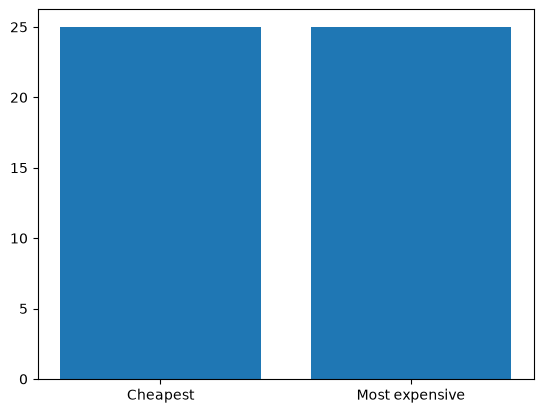

In [96]:
cheapest_counts =(cheapest["isAdult"]==0 ).sum()
most_expensive_counts =(most_expensives["isAdult"]==0).sum()
plt.bar(["Cheapest", "Most expensive"], [cheapest_counts, most_expensive_counts])
plt.show()

Every movie is made for adults only

## How does the ratings differ between budgets?

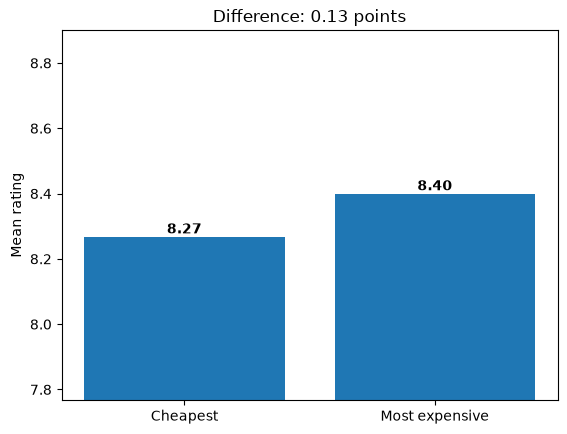

In [99]:
mean_cheapest = cheapest["averageRating"].mean()
mean_expensive = most_expensives["averageRating"].mean()

means = [mean_cheapest, mean_expensive]
labels = ["Cheapest", "Most expensive"]

plt.bar(labels, means)
plt.ylim(min(means) - 0.5, max(means) + 0.5)   # zoom in on the difference

for i, m in enumerate(means):
    plt.text(i, m, f"{m:.2f}", ha="center", va="bottom", fontweight="bold")

plt.ylabel("Mean rating")
plt.title(f"Difference: {abs(mean_expensive - mean_cheapest):.2f} points")
plt.show()